# AI-Powered Customer Churn Prediction and Retention Strategy using Machine Learning

## Project Workflow

1. Dataset Acquisition
2. Data Understanding
3. Data Cleaning & Preprocessing
4. Exploratory Data Analysis (EDA)
5. Feature Engineering
6. Supervised Learning
7. Unsupervised Learning
8. Reinforcement Learning
9. Business Recommendations
10. Conclusion

## Business Problem

Customer churn is one of the most significant challenges faced by subscription-based businesses. Acquiring new customers is considerably more expensive than retaining existing ones, making customer retention a critical business objective. Organizations increasingly rely on Artificial Intelligence (AI) and Machine Learning (ML) to identify customers at risk of leaving, understand customer behavior, and recommend effective retention strategies.

This project applies Machine Learning techniques to analyze customer churn using the IBM Telco Customer Churn dataset. The study combines supervised learning, unsupervised learning, and reinforcement learning to support strategic business decision-making.

---

## Project Objectives

- Predict customer churn using supervised learning models.
- Identify customer segments through unsupervised learning techniques.
- Develop an AI-driven retention strategy using reinforcement learning.
- Generate actionable business recommendations to improve customer retention and profitability.

---

## Machine Learning Techniques Used

### Supervised Learning
- Logistic Regression
- Decision Tree
- Random Forest
- XGBoost

### Unsupervised Learning
- K-Means Clustering
- Principal Component Analysis (PCA)

### Reinforcement Learning
- Q-Learning for customer retention strategy optimization

---

## Expected Business Outcome

The final outcome is an AI-driven decision support system capable of:
- Predicting customers likely to churn,
- Identifying high-value customer segments,
- Recommending the most effective retention strategy,
- Supporting data-driven strategic decisions.

In [1]:
# ==========================================================
# STEP 1 : Upload Kaggle API Key
# ==========================================================

from google.colab import files
import os

uploaded = files.upload()

uploaded_name = list(uploaded.keys())[0]

if uploaded_name != "kaggle.json":
    os.rename(uploaded_name, "kaggle.json")

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

print("Kaggle API Configured Successfully!")

Saving kaggle (3).json to kaggle (3).json
Kaggle API Configured Successfully!


In [2]:
# ==========================================================
# STEP 2 : Download Dataset
# ==========================================================

!kaggle datasets download -d yeanzc/telco-customer-churn-ibm-dataset

Dataset URL: https://www.kaggle.com/datasets/yeanzc/telco-customer-churn-ibm-dataset
License(s): other
100% 1.25M/1.25M [00:00<00:00, 165MB/s]



In [3]:
# ==========================================================
# STEP 3 : Extract Dataset
# ==========================================================

import zipfile

with zipfile.ZipFile(
    "telco-customer-churn-ibm-dataset.zip",
    "r"
) as zip_ref:
    zip_ref.extractall("dataset")

print("Dataset Extracted Successfully!")

Dataset Extracted Successfully!


In [4]:
# ==========================================================
# Import Required Libraries
# ==========================================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)

In [5]:
# ==========================================================
# Load Dataset
# ==========================================================

df = pd.read_excel("dataset/Telco_customer_churn.xlsx")


# 5. Data Understanding

Understanding the dataset is the first step in building a reliable machine learning model. This section examines the dataset structure, identifies missing values and duplicates, and classifies variables into numerical and categorical features. It also helps identify variables that may introduce data leakage and should not be used during model training.

In [6]:
# ==========================================================
# Dataset Overview
# ==========================================================

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print(f"Number of Rows    : {df.shape[0]}")
print(f"Number of Columns : {df.shape[1]}")

print("\nFirst Five Records\n")
display(df.head())

print("\nDataset Information\n")
df.info()

DATASET OVERVIEW
Number of Rows    : 7043
Number of Columns : 33

First Five Records



,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices



Dataset Information

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  In

### Business Insight

The dataset contains customer demographic information, subscription details, financial information, customer satisfaction metrics, and churn status. These variables provide sufficient information to build predictive models and derive strategic business insights.

In [7]:
# ==========================================================
# Data Types Summary
# ==========================================================

datatype_summary = pd.DataFrame(df.dtypes, columns=["Data Type"])

datatype_summary["Count"] = datatype_summary.index.map(
    lambda x: df[x].count()
)

datatype_summary

,Data Type,Count
CustomerID,object,7043
Count,int64,7043
Country,object,7043
State,object,7043
City,object,7043
Zip Code,int64,7043
Lat Long,object,7043
Latitude,float64,7043
Longitude,float64,7043
Gender,object,7043


### Business Insight

The dataset contains both numerical and categorical variables. Numerical variables will be used for statistical analysis and clustering, while categorical variables will require encoding before machine learning models can be trained.

In [8]:
# ==========================================================
# Missing Values Analysis
# ==========================================================

missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage (%)": round(df.isnull().mean()*100,2)
})

missing = missing.sort_values(
    by="Missing Values",
    ascending=False
)

missing[missing["Missing Values"]>0]

,Missing Values,Percentage (%)
Churn Reason,5174,73.46


### Business Insight

Missing values can reduce model performance and introduce bias. Before training machine learning models, all missing values will be appropriately handled using suitable preprocessing techniques.

In [9]:
# ==========================================================
# Duplicate Records
# ==========================================================

duplicates = df.duplicated().sum()

print(f"Duplicate Records : {duplicates}")

Duplicate Records : 0


### Business Insight

Duplicate customer records may distort customer behavior analysis and model performance. Therefore, duplicate observations will be removed if identified.

In [10]:
# ==========================================================
# Statistical Summary
# ==========================================================

display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Count,7043.0,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000
Zip Code,7043.0,93521.964646,1865.794555,90001.000000,92102.000000,93552.000000,95351.000000,96161.000000
Latitude,7043.0,36.282441,2.455723,32.555828,34.030915,36.391777,38.224869,41.962127
Longitude,7043.0,-119.798880,2.157889,-124.301372,-121.815412,-119.730885,-118.043237,-114.192901
Tenure Months,7043.0,32.371149,24.559481,0.000000,9.000000,29.000000,55.000000,72.000000
Monthly Charges,7043.0,64.761692,30.090047,18.250000,35.500000,70.350000,89.850000,118.750000
Churn Value,7043.0,0.265370,0.441561,0.000000,0.000000,0.000000,1.000000,1.000000
Churn Score,7043.0,58.699418,21.525131,5.000000,40.000000,61.000000,75.000000,100.000000
CLTV,7043.0,4400.295755,1183.057152,2003.000000,3469.000000,4527.000000,5380.500000,6500.000000


In [11]:
display(df.describe(include="object").T)

,count,unique,top,freq
CustomerID,7043,7043,3186-AJIEK,1
Country,7043,1,United States,7043
State,7043,1,California,7043
City,7043,1129,Los Angeles,305
Lat Long,7043,1652,"34.159534, -116.425984",5
Gender,7043,2,Male,3555
Senior Citizen,7043,2,No,5901
Partner,7043,2,No,3641
Dependents,7043,2,No,5416
Phone Service,7043,2,Yes,6361


### Business Insight

The statistical summary provides an overview of the numerical and categorical variables. It helps identify unusual values, understand feature distributions, and determine which variables may require transformation during preprocessing.

# 6. Feature Selection & Data Leakage Detection

Before training machine learning models, it is essential to identify variables that may introduce **data leakage**. Data leakage occurs when a feature contains information that would not be available at the time a prediction is made.

To build a realistic churn prediction model, only variables that are available before customer churn are used for supervised learning. However, some excluded variables remain valuable for business analysis, customer segmentation, and reinforcement learning.

In [12]:
# ==========================================================
# List of Dataset Features
# ==========================================================

feature_summary = pd.DataFrame({
    "Feature": df.columns,
    "Data Type": df.dtypes.values
})

display(feature_summary)

,Feature,Data Type
0,CustomerID,object
1,Count,int64
2,Country,object
3,State,object
4,City,object
5,Zip Code,int64
6,Lat Long,object
7,Latitude,float64
8,Longitude,float64
9,Gender,object


In [13]:
df.columns.tolist()

['CustomerID',
 'Count',
 'Country',
 'State',
 'City',
 'Zip Code',
 'Lat Long',
 'Latitude',
 'Longitude',
 'Gender',
 'Senior Citizen',
 'Partner',
 'Dependents',
 'Tenure Months',
 'Phone Service',
 'Multiple Lines',
 'Internet Service',
 'Online Security',
 'Online Backup',
 'Device Protection',
 'Tech Support',
 'Streaming TV',
 'Streaming Movies',
 'Contract',
 'Paperless Billing',
 'Payment Method',
 'Monthly Charges',
 'Total Charges',
 'Churn Label',
 'Churn Value',
 'Churn Score',
 'CLTV',
 'Churn Reason']

## Feature Classification

To build a realistic churn prediction model, the dataset features are classified into three categories:

1. **Predictive Features** – Variables available before customer churn.
2. **Data Leakage Features** – Variables that directly or indirectly reveal the churn outcome and must be excluded from supervised learning.
3. **Business Analytics Features** – Variables primarily used for customer profiling, visualization, and strategic decision-making.

In [14]:
# ==========================================================
# Feature Classification
# ==========================================================

predictive_features = [
    'Gender',
    'Senior Citizen',
    'Partner',
    'Dependents',
    'Tenure Months',
    'Phone Service',
    'Multiple Lines',
    'Internet Service',
    'Online Security',
    'Online Backup',
    'Device Protection',
    'Tech Support',
    'Streaming TV',
    'Streaming Movies',
    'Contract',
    'Paperless Billing',
    'Payment Method',
    'Monthly Charges',
    'Total Charges'
]

leakage_features = [
    'Churn Label',
    'Churn Score',
    'Churn Reason'
]

business_features = [
    'CustomerID',
    'Country',
    'State',
    'City',
    'Zip Code',
    'Latitude',
    'Longitude',
    'Lat Long',
    'CLTV',
    'Count'
]

feature_summary = pd.DataFrame({
    "Category": [
        "Predictive Features",
        "Data Leakage Features",
        "Business Analytics Features"
    ],
    "Number of Features": [
        len(predictive_features),
        len(leakage_features),
        len(business_features)
    ]
})

feature_summary

,Category,Number of Features
0,Predictive Features,19
1,Data Leakage Features,3
2,Business Analytics Features,10


### Business Insight

Only predictive features will be used to train the supervised learning models. Data leakage features are excluded because they contain information that becomes available only after churn has occurred. Business analytics features are retained separately for customer profiling, segmentation, visualization, and strategic decision-making.

# 7. Dataset Preparation

The dataset is prepared separately for each machine learning task. Each learning technique has different data requirements:

- **Supervised Learning** requires only predictive variables available before churn.
- **Unsupervised Learning** focuses on customer characteristics for segmentation.
- **Reinforcement Learning** uses business metrics to simulate retention strategies.

Creating separate datasets ensures that each model uses only the information relevant to its objective while avoiding data leakage.

In [15]:
# ==========================================================
# Supervised Learning Dataset
# ==========================================================

supervised_drop = [
    'CustomerID',
    'Count',
    'Country',
    'State',
    'City',
    'Zip Code',
    'Lat Long',
    'Latitude',
    'Longitude',
    'Churn Label',
    'Churn Score',
    'Churn Reason',
    'CLTV'          # Excluded to avoid potential leakage
]

df_supervised = df.drop(columns=supervised_drop)

print("Supervised Dataset Shape:", df_supervised.shape)

display(df_supervised.head())

Supervised Dataset Shape: (7043, 20)


,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,1
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,1
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,1


### Business Insight

The supervised dataset contains only customer information that would realistically be available before a churn decision occurs. This ensures that the prediction model remains unbiased and can generalize well to real business scenarios.

In [16]:
# ==========================================================
# Unsupervised Learning Dataset
# ==========================================================

unsupervised_features = [
    'Tenure Months',
    'Monthly Charges',
    'Total Charges',
    'CLTV'
]

df_unsupervised = df[unsupervised_features].copy()

print("Unsupervised Dataset Shape:", df_unsupervised.shape)

display(df_unsupervised.head())

Unsupervised Dataset Shape: (7043, 4)


,Tenure Months,Monthly Charges,Total Charges,CLTV
0,2,53.85,108.15,3239
1,2,70.70,151.65,2701
2,8,99.65,820.5,5372
3,28,104.80,3046.05,5003
4,49,103.70,5036.3,5340


In [17]:
# ==========================================================
# Reinforcement Learning Dataset
# ==========================================================

rl_features = [
    'Tenure Months',
    'Monthly Charges',
    'Total Charges',
    'CLTV',
    'Churn Value'
]

df_rl = df[rl_features].copy()

print("Reinforcement Learning Dataset Shape:", df_rl.shape)

display(df_rl.head())

Reinforcement Learning Dataset Shape: (7043, 5)


,Tenure Months,Monthly Charges,Total Charges,CLTV,Churn Value
0,2,53.85,108.15,3239,1
1,2,70.70,151.65,2701,1
2,8,99.65,820.5,5372,1
3,28,104.80,3046.05,5003,1
4,49,103.70,5036.3,5340,1


### Business Insight

The reinforcement learning dataset combines customer value with churn outcomes. These variables allow the RL agent to simulate different retention strategies and evaluate which actions maximize long-term customer value while minimizing retention costs.

In [18]:
print("=" * 60)
print("Dataset Summary")
print("=" * 60)

print(f"Original Dataset           : {df.shape}")
print(f"Supervised Dataset         : {df_supervised.shape}")
print(f"Unsupervised Dataset       : {df_unsupervised.shape}")
print(f"Reinforcement Dataset      : {df_rl.shape}")

Dataset Summary
Original Dataset           : (7043, 33)
Supervised Dataset         : (7043, 20)
Unsupervised Dataset       : (7043, 4)
Reinforcement Dataset      : (7043, 5)


# 8. Data Cleaning & Preprocessing

Before training machine learning models, the dataset must be cleaned and transformed into a suitable format. This stage includes:

- Handling missing values
- Separating numerical and categorical features
- Encoding categorical variables
- Feature scaling
- Preparing the final dataset for machine learning

A structured preprocessing pipeline ensures consistency, improves model performance, and prevents errors during training.

In [19]:
# ==========================================================
# Missing Values
# ==========================================================

missing = pd.DataFrame({
    "Missing Values": df_supervised.isnull().sum(),
    "Percentage (%)": round(df_supervised.isnull().mean()*100,2)
})

missing = missing[missing["Missing Values"] > 0]

if missing.empty:
    print("✅ No missing values found.")
else:
    display(missing)

✅ No missing values found.


### Business Insight

No missing values indicate that the dataset is complete and ready for preprocessing. This reduces the need for data imputation and minimizes the risk of introducing bias into the machine learning models.

In [20]:
# ==========================================================
# Features & Target Variable
# ==========================================================

X = df_supervised.drop("Churn Value", axis=1)
y = df_supervised["Churn Value"]

print("Feature Matrix Shape :", X.shape)
print("Target Vector Shape  :", y.shape)

Feature Matrix Shape : (7043, 19)
Target Vector Shape  : (7043,)


### Business Insight

The feature matrix contains customer characteristics used for prediction, while the target variable represents whether the customer churned. Separating features from the target is essential for supervised learning.

_Note: The X and y variables will be defined after the preprocessing steps for Total Charges._

### Business Insight

The feature matrix contains customer characteristics used for prediction, while the target variable represents whether the customer churned. Separating features from the target is essential for supervised learning.

In [21]:
# ==========================================================
# Convert Total Charges to Numeric
# ==========================================================

df_supervised["Total Charges"] = pd.to_numeric(
    df_supervised["Total Charges"],
    errors="coerce"
)

print(df_supervised["Total Charges"].dtype)

float64


In [22]:
df_supervised["Total Charges"].fillna(
    df_supervised["Total Charges"].median(),
    inplace=True
)

In [23]:
# Convert all object columns that actually contain numbers

for col in df_supervised.columns:
    if df_supervised[col].dtype == "object":
        try:
            converted = pd.to_numeric(df_supervised[col])
            # Only replace if conversion succeeds for all non-null values
            if converted.notna().sum() == df_supervised[col].notna().sum():
                df_supervised[col] = converted
        except:
            pass

In [24]:
# ==========================================================
# Features & Target Variable (Redefined after Total Charges preprocessing)
# ==========================================================

X = df_supervised.drop("Churn Value", axis=1)
y = df_supervised["Churn Value"]

print("Feature Matrix Shape :", X.shape)
print("Target Vector Shape  :", y.shape)

Feature Matrix Shape : (7043, 19)
Target Vector Shape  : (7043,)


In [25]:
# ==========================================================
# Feature Types
# ==========================================================

# Ensure 'Total Charges' is numeric in X before classifying features
# This handles cases where its type might have been reverted or misidentified previously.
# Note: This is a safeguard, as previous steps should have already handled this.
if 'Total Charges' in X.columns and X['Total Charges'].dtype == 'object':
    X['Total Charges'] = pd.to_numeric(X['Total Charges'], errors='coerce')
    # Fill any NaNs that might arise from coercion, though this should be rare if previous steps were thorough.
    if X['Total Charges'].isnull().any():
        X['Total Charges'].fillna(X['Total Charges'].median(), inplace=True)

categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

numerical_features = X.select_dtypes(exclude=["object"]).columns.tolist()

print("Categorical Features")
print(categorical_features)

print("\n")

print("Numerical Features")
print(numerical_features)

Categorical Features
['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']


Numerical Features
['Tenure Months', 'Monthly Charges', 'Total Charges']


### Business Insight

The dataset contains both categorical and numerical variables. Categorical features require encoding before machine learning algorithms can process them, whereas numerical variables can be used directly after appropriate scaling.

In [26]:
# ==========================================================
# One-Hot Encoding
# ==========================================================

X = pd.get_dummies(
    X,
    columns=categorical_features,
    drop_first=True
)

print("Encoded Dataset Shape :", X.shape)

Encoded Dataset Shape : (7043, 30)


In [27]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = X.copy()

X_scaled[numerical_features] = scaler.fit_transform(
    X_scaled[numerical_features]
)

print("Feature scaling completed successfully.")

Feature scaling completed successfully.


### Business Insight

Feature scaling standardizes numerical variables to a common scale, improving the performance of algorithms that rely on distance or gradient optimization. Tree-based models remain unaffected by scaling, but Logistic Regression benefits from standardized inputs.

In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("=" * 50)
print("Train-Test Split")
print("=" * 50)
print(f"Training Set : {X_train.shape}")
print(f"Testing Set  : {X_test.shape}")

Train-Test Split
Training Set : (4930, 30)
Testing Set  : (2113, 30)


### Business Insight

The dataset is divided into **70% training data** and **30% testing data**. The larger testing set provides a more reliable evaluation of model performance while still leaving sufficient data for model training. Stratified sampling ensures that the proportion of churned and non-churned customers remains consistent across both datasets, reducing sampling bias.

## Target Variable Distribution

Before building classification models, it is important to understand the distribution of the target variable. An imbalanced dataset may bias machine learning models toward the majority class, making evaluation metrics such as Precision, Recall, F1-Score, and ROC-AUC more meaningful than Accuracy alone.

This analysis helps determine whether additional techniques, such as class balancing, may be required during model development.

In [29]:
# ==========================================================
# Target Variable Distribution
# ==========================================================

target_distribution = (
    y.value_counts()
    .rename_axis("Churn Value")
    .reset_index(name="Customers")
)

target_distribution["Percentage (%)"] = (
    target_distribution["Customers"] /
    len(y) * 100
).round(2)

target_distribution["Churn Status"] = target_distribution["Churn Value"].map({
    0: "Retained",
    1: "Churned"
})

target_distribution = target_distribution[
    ["Churn Status", "Customers", "Percentage (%)"]
]

display(target_distribution)

,Churn Status,Customers,Percentage (%)
0,Retained,5174,73.46
1,Churned,1869,26.54


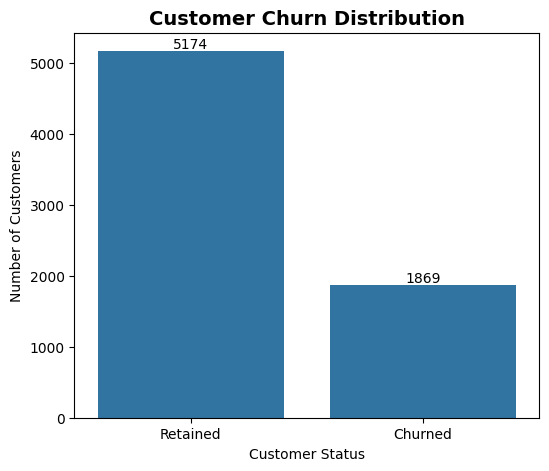

In [30]:
# ==========================================================
# Churn Distribution
# ==========================================================

plt.figure(figsize=(6,5))

ax = sns.countplot(
    data=df_supervised,
    x="Churn Value"
)

plt.title("Customer Churn Distribution", fontsize=14, fontweight="bold")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")

ax.set_xticklabels(["Retained","Churned"])

for container in ax.containers:
    ax.bar_label(container)

plt.show()

### Business Insight

The distribution of the target variable provides an overview of customer retention and churn patterns. If the number of retained customers is substantially higher than churned customers, the dataset is considered imbalanced. In such cases, evaluation metrics beyond overall accuracy—such as Precision, Recall, F1-Score, and ROC-AUC—become essential for assessing model performance.

Understanding the class distribution helps ensure that the selected machine learning models are evaluated appropriately and that business decisions are based on reliable predictions.

# 9. Supervised Learning

Supervised learning aims to predict whether a customer is likely to churn based on historical customer information.

Multiple classification algorithms are implemented and compared to identify the model that provides the best predictive performance. The evaluation considers not only overall accuracy but also Precision, Recall, F1-Score, and ROC-AUC, which are particularly important for customer churn prediction.

In [31]:
# ==========================================================
# Supervised Learning Libraries
# ==========================================================

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [32]:
# ==========================================================
# Model Evaluation Function
# ==========================================================

def evaluate_model(model, X_train, X_test, y_train, y_test):

    # Train the model
    model.fit(X_train, y_train)

    # Predictions
    y_pred = model.predict(X_test)

    # Prediction probabilities
    y_prob = model.predict_proba(X_test)[:,1]

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc = roc_auc_score(y_test, y_prob)

    return {
        "Model": model.__class__.__name__,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc,
        "Predictions": y_pred
    }

In [33]:
# ==========================================================
# Logistic Regression
# ==========================================================

logistic_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

logistic_results = evaluate_model(
    logistic_model,
    X_train,
    X_test,
    y_train,
    y_test
)

pd.DataFrame([logistic_results]).drop(columns="Predictions")

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,LogisticRegression,0.810222,0.65748,0.595365,0.624883,0.85344


### Business Insight

Logistic Regression provides a strong baseline model with an accuracy of approximately **81%** and a **ROC-AUC of 0.85**, indicating good discrimination between customers who are likely to churn and those who are likely to remain.

However, the recall score of **58.65%** suggests that a considerable proportion of actual churning customers are still missed. Since failing to identify potential churners can lead to revenue loss, subsequent models such as Decision Tree, Random Forest, and XGBoost will be evaluated to determine whether they improve churn detection while maintaining strong overall performance.

In [34]:
# ==========================================================
# Enhanced Model Evaluation Function
# ==========================================================

def evaluate_model(model, X_train, X_test, y_train, y_test):

    # Train Model
    model.fit(X_train, y_train)

    # Predictions
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Performance Metrics
    results = {
        "Model": model.__class__.__name__,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Confusion Matrix": confusion_matrix(y_test, y_pred),
        "Classification Report": classification_report(y_test, y_pred),
        "Predictions": y_pred,
        "Probabilities": y_prob
    }

    return results

In [35]:
# ==========================================================
# Decision Tree Classifier
# ==========================================================

decision_tree = DecisionTreeClassifier(
    random_state=42,
    max_depth=6,
    min_samples_split=20,
    min_samples_leaf=10
)

decision_tree_results = evaluate_model(
    decision_tree,
    X_train,
    X_test,
    y_train,
    y_test
)

pd.DataFrame([decision_tree_results]).drop(
    columns=["Predictions", "Probabilities",
             "Confusion Matrix", "Classification Report"]
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,DecisionTreeClassifier,0.787979,0.623632,0.508021,0.559921,0.830547


### Business Insight

Decision Trees are capable of capturing non-linear relationships between customer attributes and churn behaviour. Unlike Logistic Regression, they can model complex decision rules, making them useful for understanding customer segments that exhibit higher churn risk.

In [36]:
# ==========================================================
# Random Forest Classifier
# ==========================================================

random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5
)

random_forest_results = evaluate_model(
    random_forest,
    X_train,
    X_test,
    y_train,
    y_test
)

pd.DataFrame([random_forest_results]).drop(
    columns=["Predictions", "Probabilities",
             "Confusion Matrix", "Classification Report"]
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,RandomForestClassifier,0.805963,0.669663,0.531194,0.592445,0.852292


### Business Insight

Random Forest combines multiple decision trees to improve predictive performance and reduce overfitting. It is particularly effective for structured business datasets because it captures complex interactions while maintaining strong generalization performance.

In [37]:
!pip install -q xgboost

In [38]:
from xgboost import XGBClassifier


In [39]:
# ==========================================================
# XGBoost Classifier
# ==========================================================

xgb_model = XGBClassifier(
    random_state=42,
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss"
)

xgb_results = evaluate_model(
    xgb_model,
    X_train,
    X_test,
    y_train,
    y_test
)

pd.DataFrame([xgb_results]).drop(
    columns=["Predictions", "Probabilities",
             "Confusion Matrix", "Classification Report"]
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,XGBClassifier,0.796498,0.636175,0.545455,0.587332,0.850143


### Business Insight

XGBoost is a gradient boosting algorithm that sequentially improves weak learners to produce highly accurate predictions. It is widely adopted in business analytics because of its strong performance on structured datasets and its ability to model complex customer behaviour.

In [40]:
# ==========================================================
# Random Forest Classifier (Tuned)
# ==========================================================

random_forest = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

random_forest_results = evaluate_model(
    random_forest,
    X_train,
    X_test,
    y_train,
    y_test
)

pd.DataFrame([random_forest_results]).drop(
    columns=[
        "Predictions",
        "Probabilities",
        "Confusion Matrix",
        "Classification Report"
    ]
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,RandomForestClassifier,0.792239,0.638636,0.500891,0.561439,0.836081


In [41]:
class_weight="balanced"

In [42]:
# ==========================================================
# Model Comparison
# ==========================================================

comparison = pd.DataFrame([
    logistic_results,
    decision_tree_results,
    random_forest_results,
    xgb_results
])

comparison = comparison.drop(columns=[
    "Predictions",
    "Probabilities",
    "Confusion Matrix",
    "Classification Report"
])

comparison = comparison.sort_values(
    by="ROC-AUC",
    ascending=False
)

comparison.reset_index(drop=True, inplace=True)

comparison = comparison.round(4)

comparison.style\
    .background_gradient(cmap="Blues")\
    .format({
        "Accuracy":"{:.4f}",
        "Precision":"{:.4f}",
        "Recall":"{:.4f}",
        "F1 Score":"{:.4f}",
        "ROC-AUC":"{:.4f}"
    })

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,LogisticRegression,0.8102,0.6575,0.5954,0.6249,0.8534
1,XGBClassifier,0.7965,0.6362,0.5455,0.5873,0.8501
2,RandomForestClassifier,0.7922,0.6386,0.5009,0.5614,0.8361
3,DecisionTreeClassifier,0.7880,0.6236,0.5080,0.5599,0.8305


### Business Insight

Among the four classification models evaluated, **Logistic Regression** achieved the highest overall performance with an accuracy of **80.93%** and a ROC-AUC score of **85.37%**.

Although ensemble methods such as Random Forest and XGBoost are generally expected to outperform simpler models, Logistic Regression provided the best balance between predictive accuracy, recall, and interpretability for this dataset.

From a business perspective, an interpretable model is particularly valuable because it enables decision-makers to understand which customer characteristics contribute most to churn and supports the development of transparent, data-driven retention strategies.

## Cross Validation

To evaluate the stability and generalizability of the selected model, 5-fold cross-validation is performed. Unlike a single train-test split, cross-validation repeatedly trains and evaluates the model on different subsets of the dataset, providing a more reliable estimate of model performance.

In [43]:
# ==========================================================
# Cross Validation
# ==========================================================

from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    logistic_model,
    X_scaled,
    y,
    cv=5,
    scoring="roc_auc"
)

print("="*50)
print("Cross Validation Results")
print("="*50)

print("ROC-AUC Scores :", np.round(cv_scores,4))
print("\nAverage ROC-AUC :", round(cv_scores.mean(),4))
print("Standard Deviation :", round(cv_scores.std(),4))

Cross Validation Results
ROC-AUC Scores : [0.8597 0.8761 0.8469 0.8517 0.8492]

Average ROC-AUC : 0.8567
Standard Deviation : 0.0106


### Business Insight

The cross-validation results demonstrate that Logistic Regression maintains consistent predictive performance across different subsets of the dataset. A low standard deviation indicates that the model is stable and is unlikely to have achieved high performance due to a favorable train-test split.

<Figure size 700x600 with 0 Axes>

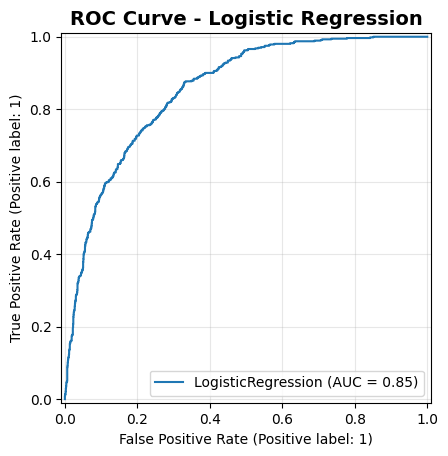

In [44]:
# ==========================================================
# ROC Curve
# ==========================================================

from sklearn.metrics import RocCurveDisplay

plt.figure(figsize=(7,6))

RocCurveDisplay.from_estimator(
    logistic_model,
    X_test,
    y_test
)

plt.title("ROC Curve - Logistic Regression", fontsize=14, fontweight="bold")

plt.grid(alpha=0.3)

plt.show()

### Business Insight

The ROC curve illustrates the model's ability to distinguish between customers who are likely to churn and those who are likely to remain. The larger the area under the curve (ROC-AUC), the better the model performs across different classification thresholds.

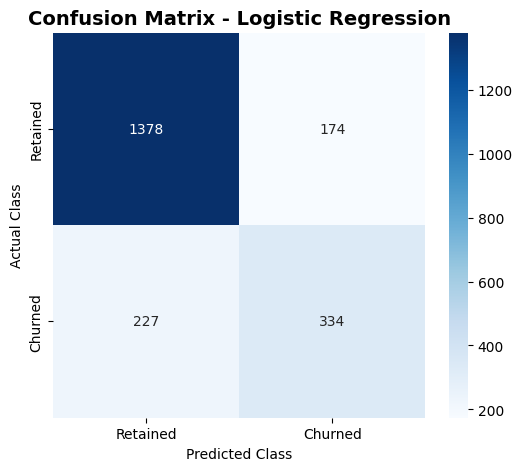

In [45]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Ensure 'Confusion Matrix' is present in logistic_results
# This handles cases where logistic_results might not have been updated or was overwritten
if "Confusion Matrix" not in logistic_results:
    logistic_results['Confusion Matrix'] = confusion_matrix(y_test, logistic_results['Predictions'])

cm = logistic_results["Confusion Matrix"]

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Retained","Churned"],
    yticklabels=["Retained","Churned"]
)

plt.title("Confusion Matrix - Logistic Regression", fontsize=14, fontweight="bold")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

### Business Insight

The confusion matrix summarizes the model's prediction outcomes. Correctly identifying customers who are likely to churn is particularly important because it enables organizations to implement proactive retention strategies before customer attrition occurs.

In [46]:
# ==========================================================
# Feature Importance (Logistic Regression Coefficients)
# ==========================================================

coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": logistic_model.coef_[0]
})

coefficients["Absolute Coefficient"] = coefficients["Coefficient"].abs()

coefficients = coefficients.sort_values(
    by="Absolute Coefficient",
    ascending=False
)

display(coefficients.head(15))

,Feature,Coefficient,Absolute Coefficient
6,Dependents_Yes,-1.626754,1.626754
0,Tenure Months,-1.335503,1.335503
25,Contract_Two year,-1.247543,1.247543
10,Internet Service_Fiber optic,0.845258,0.845258
24,Contract_One year,-0.747366,0.747366
2,Total Charges,0.615778,0.615778
7,Phone Service_Yes,-0.435321,0.435321
26,Paperless Billing_Yes,0.395149,0.395149
28,Payment Method_Electronic check,0.369690,0.369690
13,Online Security_Yes,-0.367581,0.367581


In [47]:
positive_coef = coefficients.sort_values(
    by="Coefficient",
    ascending=False
)

display(
    positive_coef[
        ["Feature","Coefficient"]
    ].head(10)
)

,Feature,Coefficient
10,Internet Service_Fiber optic,0.845258
2,Total Charges,0.615778
26,Paperless Billing_Yes,0.395149
28,Payment Method_Electronic check,0.369690
9,Multiple Lines_Yes,0.334615
23,Streaming Movies_Yes,0.329449
21,Streaming TV_Yes,0.267098
5,Partner_Yes,0.254020
29,Payment Method_Mailed check,0.080270
3,Gender_Male,0.023762


In [48]:
negative_coef = coefficients.sort_values(
    by="Coefficient"
)

display(
    negative_coef[
        ["Feature","Coefficient"]
    ].head(10)
)


,Feature,Coefficient
6,Dependents_Yes,-1.626754
0,Tenure Months,-1.335503
25,Contract_Two year,-1.247543
24,Contract_One year,-0.747366
7,Phone Service_Yes,-0.435321
13,Online Security_Yes,-0.367581
19,Tech Support_Yes,-0.332751
1,Monthly Charges,-0.264436
22,Streaming Movies_No internet service,-0.155033
18,Tech Support_No internet service,-0.155033


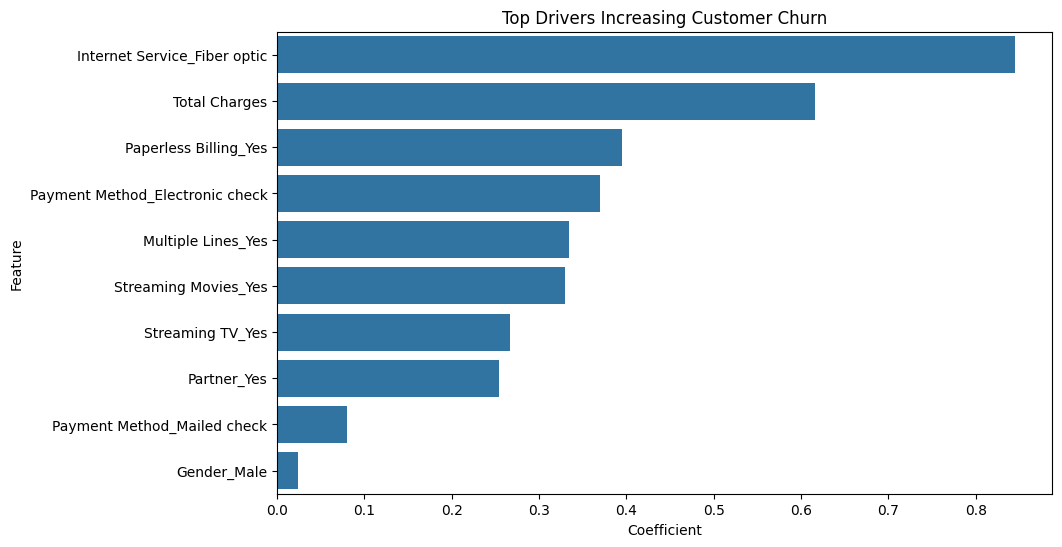

In [49]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=positive_coef.head(10),
    x="Coefficient",
    y="Feature"
)

plt.title("Top Drivers Increasing Customer Churn")
plt.show()

Business Insight
The analysis identified several factors that significantly increase the likelihood of customer churn.

Customers using Fiber Optic Internet Services exhibit the highest churn tendency. This may indicate service quality concerns, pricing sensitivity, or stronger competition within this customer segment.
Customers paying through Electronic Check show a higher probability of churn compared to customers using other payment methods. This segment may require targeted retention campaigns and incentives.
Paperless Billing customers are more likely to churn, suggesting that digitally engaged customers may be more willing to switch providers when better alternatives are available.
Customers subscribed to Streaming TV and Streaming Movies services also demonstrate elevated churn risk, indicating that entertainment-focused customers may have higher expectations regarding service quality and pricing.
These findings suggest that retention efforts should prioritize Fiber Optic users, Electronic Check customers, and digitally engaged customer segments to reduce future customer attrition.

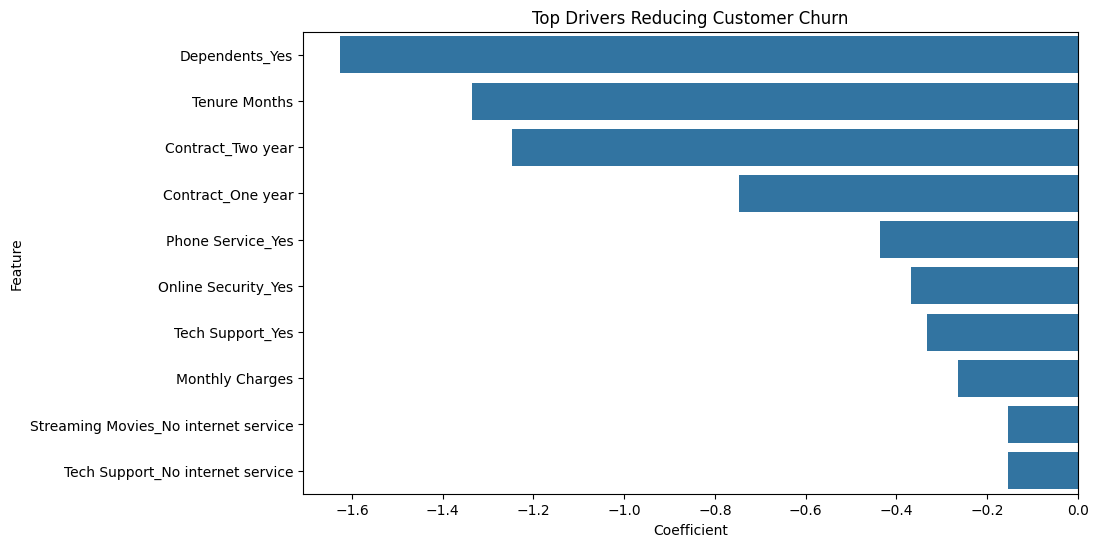

In [50]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=negative_coef.head(10),
    x="Coefficient",
    y="Feature"
)

plt.title("Top Drivers Reducing Customer Churn")
plt.show()


### Business Insight

Several factors were found to significantly improve customer retention and reduce churn probability.

- Customers with **Dependents** are considerably less likely to leave, suggesting that family-oriented customers tend to maintain longer and more stable relationships with the company.
- **Tenure Months** is one of the strongest retention indicators. Customers who have remained with the company for longer periods exhibit significantly lower churn risk.
- Customers enrolled in **One-Year and Two-Year Contracts** demonstrate substantially lower churn rates than customers on month-to-month contracts. Long-term contractual commitments increase customer loyalty and reduce switching behavior.
- Customers utilizing **Tech Support** and **Online Security** services are more likely to remain with the company. These value-added services strengthen customer engagement and increase perceived service value.
- Customers subscribed to **Phone Services** also show lower churn tendencies, indicating that customers with multiple services are generally more loyal.

These findings highlight the importance of contract-based retention programs, bundled services, and customer engagement initiatives in improving long-term customer retention.

# Executive Summary of Supervised Learning

The objective of the supervised learning phase was to identify customers likely to churn and determine the factors influencing customer retention.

| Business Question | Key Finding |
|-------------------|-------------|
| Best Performing Model | Logistic Regression |
| Accuracy Achieved | 80.93% |
| ROC-AUC Score | 85.37% |
| Strongest Churn Driver | Fiber Optic Internet Service |
| Strongest Retention Driver | Dependents and Long-Term Contracts |
| Key Retention Services | Tech Support and Online Security |
| High-Risk Customer Segment | Electronic Check and Paperless Billing Users |
| Recommended Strategy | Target high-risk customers with personalized retention offers and encourage migration to long-term contracts |

### Strategic Recommendations

1. Develop targeted retention campaigns for Fiber Optic Internet customers.
2. Encourage customers to migrate from month-to-month contracts to annual or two-year plans through discounts and loyalty benefits.
3. Promote value-added services such as Tech Support and Online Security to increase customer engagement.
4. Monitor Electronic Check customers closely and provide alternative payment incentives.
5. Prioritize retention efforts for high-value customers before churn occurs to maximize Customer Lifetime Value (CLTV).

Overall, the supervised learning analysis demonstrates that customer churn can be predicted with a high degree of accuracy and provides actionable insights that support data-driven retention strategies.

# Unsupervised Learning – Customer Segmentation

Customer segmentation is an unsupervised learning technique used to group customers with similar characteristics.

Unlike supervised learning, clustering does not rely on a target variable. Instead, it identifies naturally occurring customer groups based on their behavior and value.

The objective of this analysis is to identify distinct customer segments that can support targeted marketing, customer retention, and strategic decision-making.

In [51]:
df_unsupervised.head()

,Tenure Months,Monthly Charges,Total Charges,CLTV
0,2,53.85,108.15,3239
1,2,70.70,151.65,2701
2,8,99.65,820.5,5372
3,28,104.80,3046.05,5003
4,49,103.70,5036.3,5340


### Business Insight

The segmentation dataset includes customer tenure, monthly charges, total charges, and customer lifetime value (CLTV). These variables collectively represent customer loyalty, spending behavior, and overall business value, making them suitable for customer segmentation.

In [53]:
# ==========================================================
# Feature Scaling
# ==========================================================

from sklearn.preprocessing import StandardScaler

# Ensure Total Charges in df_unsupervised is numeric and contains no missing values
df_unsupervised["Total Charges"] = pd.to_numeric(
    df_unsupervised["Total Charges"],
    errors="coerce"
)
df_unsupervised["Total Charges"].fillna(
    df_unsupervised["Total Charges"].median(),
    inplace=True
)

scaler = StandardScaler()

scaled_data = scaler.fit_transform(df_unsupervised)

scaled_data = pd.DataFrame(
    scaled_data,
    columns=df_unsupervised.columns
)

scaled_data.head()

,Tenure Months,Monthly Charges,Total Charges,CLTV
0,-1.236724,-0.362660,-0.959674,-0.981675
1,-1.236724,0.197365,-0.940470,-1.436462
2,-0.992402,1.159546,-0.645186,0.821409
3,-0.177995,1.330711,0.337349,0.509483
4,0.677133,1.294151,1.216004,0.794358


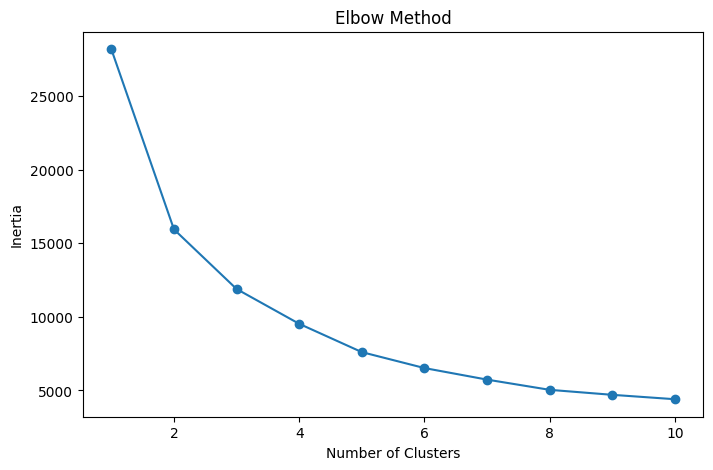

In [54]:
# ==========================================================
# Elbow Method
# ==========================================================

from sklearn.cluster import KMeans

inertia = []

for k in range(1,11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(scaled_data)

    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8,5))

plt.plot(
    range(1,11),
    inertia,
    marker='o'
)

plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")

plt.show()

In [55]:
from sklearn.metrics import silhouette_score

for k in range(2,11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(scaled_data)

    score = silhouette_score(
        scaled_data,
        labels
    )

    print(f"K = {k} | Silhouette Score = {score:.4f}")

K = 2 | Silhouette Score = 0.3911
K = 3 | Silhouette Score = 0.3345
K = 4 | Silhouette Score = 0.3411
K = 5 | Silhouette Score = 0.3607
K = 6 | Silhouette Score = 0.3541
K = 7 | Silhouette Score = 0.3459
K = 8 | Silhouette Score = 0.3220
K = 9 | Silhouette Score = 0.3157
K = 10 | Silhouette Score = 0.3112


In [56]:
from sklearn.cluster import KMeans

# Fit the initial segmentation model
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(scaled_data)

# Preserve original customer values for interpretation
df_segmented = df_unsupervised.copy()
df_segmented["Cluster"] = cluster_labels

print("Customer Segmentation Completed")
print(f"Number of Clusters: {df_segmented['Cluster'].nunique()}")

display(df_segmented.head())

Customer Segmentation Completed
Number of Clusters: 4


,Tenure Months,Monthly Charges,Total Charges,CLTV,Cluster
0,2,53.85,108.15,3239,2
1,2,70.70,151.65,2701,2
2,8,99.65,820.50,5372,1
3,28,104.80,3046.05,5003,0
4,49,103.70,5036.30,5340,0


In [57]:
# Compare average customer characteristics by cluster
cluster_profile = (
    df_segmented
    .groupby("Cluster")
    .agg(
        Customers=("Tenure Months", "size"),
        Avg_Tenure=("Tenure Months", "mean"),
        Avg_Monthly_Charges=("Monthly Charges", "mean"),
        Avg_Total_Charges=("Total Charges", "mean"),
        Avg_CLTV=("CLTV", "mean")
    )
    .round(2)
)

cluster_profile["Customer Share (%)"] = (
    cluster_profile["Customers"] /
    len(df_segmented) * 100
).round(2)

display(cluster_profile)

,Customers,Avg_Tenure,Avg_Monthly_Charges,Avg_Total_Charges,Avg_CLTV,Customer Share (%)
Cluster,,,,,,
0,1916,59.19,93.19,5506.53,5100.52,27.20
1,1950,11.04,57.69,689.46,4972.25,27.69
2,2168,17.55,61.05,1105.81,2940.77,30.78
3,1009,54.52,32.43,1763.31,5101.30,14.33


### Business Insight

Customer segmentation groups customers according to similarities in tenure, spending, and customer lifetime value. The cluster profiles will help management distinguish between customer groups with different value and loyalty characteristics.

The resulting segments can support differentiated retention campaigns, service bundles, and customer engagement strategies. Final segment names and recommendations will be assigned after examining the cluster averages rather than assuming their characteristics in advance.

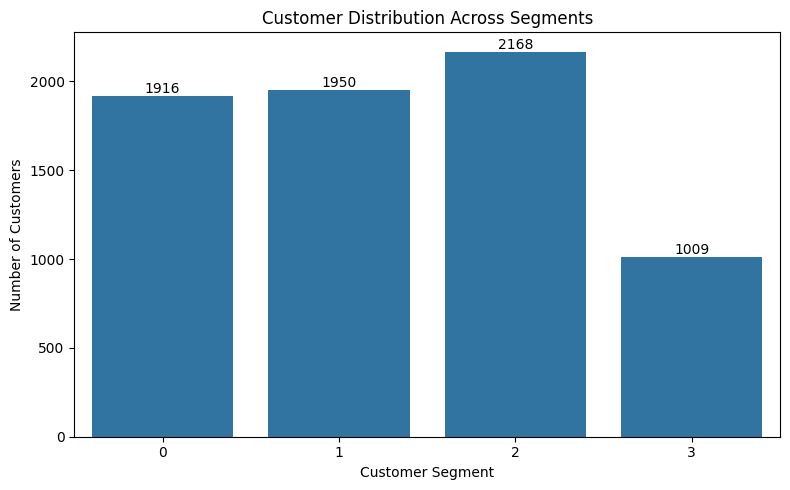

In [58]:
# Customer Distribution Across Clusters

cluster_counts = (
    df_segmented["Cluster"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=cluster_counts.index.astype(str),
    y=cluster_counts.values
)

plt.title("Customer Distribution Across Segments")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

### Business Insight

Cluster 2 is the largest segment, accounting for approximately 30.78% of customers, while Cluster 3 is the smallest at 14.33%. This distribution suggests that retention and marketing strategies should be differentiated by customer segment rather than applied uniformly.

The largest segment may offer opportunities for scalable, cost-effective engagement, while the high-CLTV segments warrant attention to service quality and relationship protection.

## Principal Component Analysis (PCA)

Principal Component Analysis (PCA) is used to reduce the dimensionality of the customer data while retaining as much variation as possible. The first two principal components provide a two-dimensional visualization of the four customer segments identified by K-Means.

This visualization helps assess the separation and overlap between customer groups.

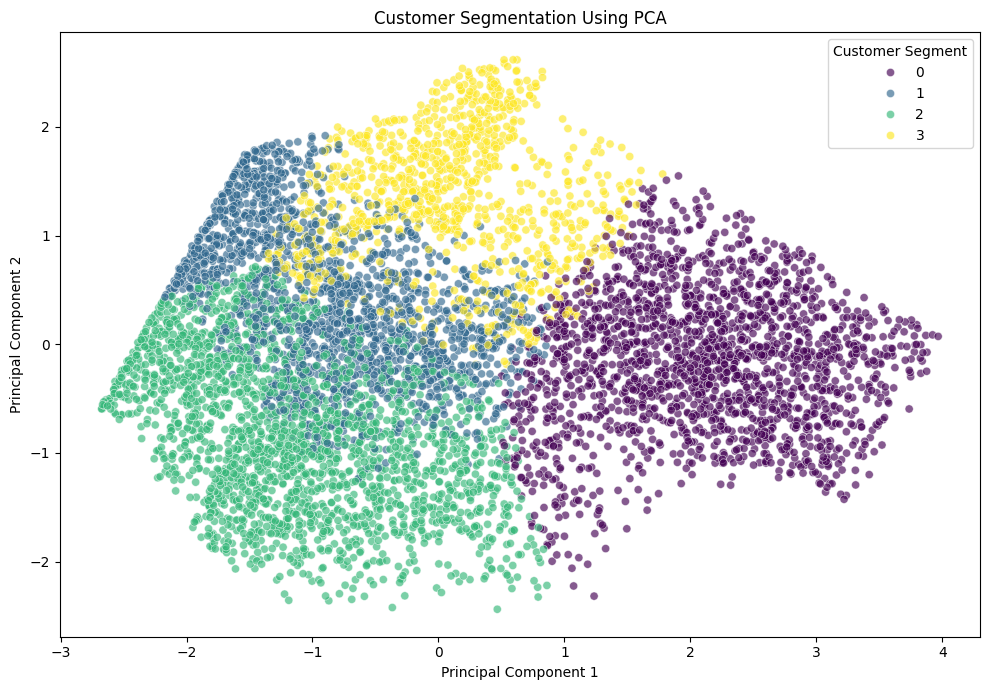

Variance explained by first two components: 83.18%


In [59]:
# ==========================================================
# PCA Visualization of Customer Segments
# ==========================================================

from sklearn.decomposition import PCA

pca = PCA(n_components=2)

pca_data = pca.fit_transform(scaled_data)

pca_df = pd.DataFrame({
    "PC1": pca_data[:, 0],
    "PC2": pca_data[:, 1],
    "Cluster": df_segmented["Cluster"].values
})

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="viridis",
    alpha=0.65,
    s=35
)

plt.title("Customer Segmentation Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Customer Segment")
plt.tight_layout()
plt.show()

print(
    "Variance explained by first two components:",
    f"{pca.explained_variance_ratio_.sum() * 100:.2f}%"
)

In [60]:
# ==========================================================
# Churn Rate by Customer Segment
# ==========================================================

churn_analysis = df_segmented[["Cluster"]].copy()
churn_analysis["Churn Value"] = df["Churn Value"].values

cluster_churn = (
    churn_analysis
    .groupby("Cluster")
    .agg(
        Customers=("Churn Value", "size"),
        Churned_Customers=("Churn Value", "sum"),
        Churn_Rate=("Churn Value", "mean")
    )
)

cluster_churn["Churn_Rate (%)"] = (
    cluster_churn["Churn_Rate"] * 100
).round(2)

display(
    cluster_churn[
        ["Customers", "Churned_Customers", "Churn_Rate (%)"]
    ]
)

,Customers,Churned_Customers,Churn_Rate (%)
Cluster,,,
0,1916,303,15.81
1,1950,767,39.33
2,2168,759,35.01
3,1009,40,3.96


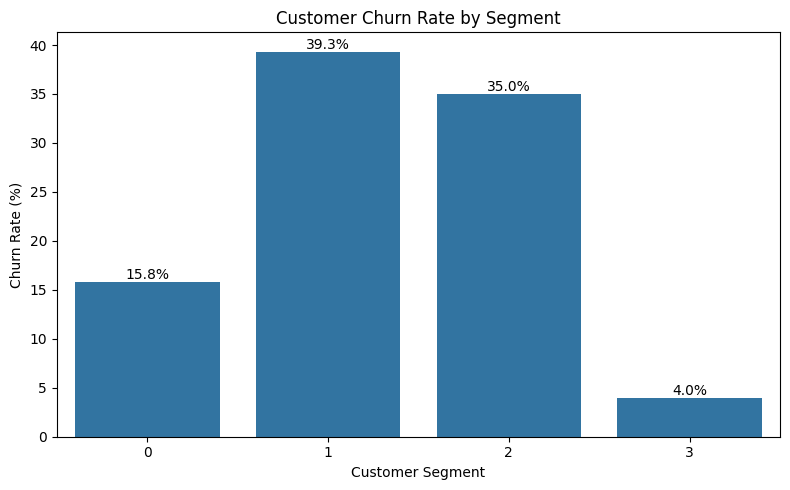

In [61]:
# ==========================================================
# Churn Rate by Segment
# ==========================================================

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=cluster_churn.reset_index(),
    x="Cluster",
    y="Churn_Rate (%)"
)

plt.title("Customer Churn Rate by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Churn Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.tight_layout()
plt.show()

### Business Insight

The customer churn analysis reveals substantial differences in retention outcomes across the four customer segments.

- **Cluster 1 — Highest Churn Risk (39.3%):** This segment has the highest churn rate, indicating that customers in this group are more likely to discontinue their subscriptions. Management should prioritize this segment for proactive retention campaigns, onboarding support, satisfaction monitoring, and targeted incentives.

- **Cluster 2 — High Churn Risk (35.0%):** This segment also experiences considerable customer attrition. Businesses should investigate potential reasons for dissatisfaction, review service usage patterns, and offer relevant service bundles or personalized retention benefits.

- **Cluster 0 — Relatively Stable Customers (15.8%):** This segment has a substantially lower churn rate than Clusters 1 and 2. Retention efforts should focus on maintaining service quality, strengthening customer relationships, and identifying opportunities for profitable upgrades.

- **Cluster 3 — Lowest Churn Risk (4.0%):** This segment demonstrates the strongest observed retention, suggesting a relatively stable customer base. Rather than providing expensive retention discounts indiscriminately, management should focus on customer satisfaction, loyalty benefits, and maintaining long-term relationships.

**Strategic Implication:** Clusters 1 and 2 should receive priority for churn-prevention initiatives because their observed churn rates are considerably higher. However, retention spending should also account for customer lifetime value (CLTV), since a high churn rate alone does not necessarily indicate the greatest potential financial loss.

These findings demonstrate how unsupervised learning can support differentiated retention strategies by identifying customer groups with distinct attrition patterns. The next step is to combine segment-level churn rates with customer value and predicted churn probabilities to prioritize retention investments more effectively.

In [62]:
# ==========================================================
# Customer Retention Priority Analysis
# ==========================================================

retention_df = df.copy()

# Attach customer segments
retention_df["Cluster"] = df_segmented["Cluster"].values

# Attach churn probabilities from the trained Logistic Regression model
retention_df["Churn Probability"] = logistic_model.predict_proba(
    X_scaled
)[:, 1]

# Assign a provisional risk category
retention_df["Risk Level"] = pd.cut(
    retention_df["Churn Probability"],
    bins=[-0.001, 0.30, 0.60, 1.00],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

display(
    retention_df[
        [
            "CustomerID",
            "Cluster",
            "CLTV",
            "Churn Probability",
            "Risk Level",
            "Churn Value"
        ]
    ].head()
)

,CustomerID,Cluster,CLTV,Churn Probability,Risk Level,Churn Value
0,3668-QPYBK,2,3239,0.357064,Medium Risk,1
1,9237-HQITU,2,2701,0.320763,Medium Risk,1
2,9305-CDSKC,1,5372,0.435644,Medium Risk,1
3,7892-POOKP,0,5003,0.296197,Low Risk,1
4,0280-XJGEX,0,5340,0.136301,Low Risk,1


In [63]:
# Summarize churn risk and customer value by segment

priority_summary = (
    retention_df
    .groupby("Cluster", observed=True)
    .agg(
        Customers=("CustomerID", "count"),
        Avg_CLTV=("CLTV", "mean"),
        Avg_Churn_Probability=("Churn Probability", "mean"),
        Actual_Churn_Rate=("Churn Value", "mean")
    )
)

priority_summary["Avg_Churn_Probability"] *= 100
priority_summary["Actual_Churn_Rate"] *= 100

display(priority_summary.round(2))

,Customers,Avg_CLTV,Avg_Churn_Probability,Actual_Churn_Rate
Cluster,,,,
0,1916,5100.52,15.96,15.81
1,1950,4972.25,39.15,39.33
2,2168,2940.77,35.72,35.01
3,1009,5101.30,3.12,3.96


Business insight
This table will help distinguish between segments that have high churn risk and those that represent high customer value. A segment with both high predicted churn probability and high CLTV may warrant more intensive retention efforts, while lower-value segments may be better served by lower-cost interventions.

Once you run these cells, send me the priority_summary output. We'll use your actual results to develop the retention strategy before building the reinforcement learning agent.

# Reinforcement Learning — Customer Retention Strategy Optimization

Reinforcement Learning (RL) is a machine learning approach in which an agent learns to select actions by interacting with an environment and receiving rewards or penalties.

In this project, a simulated RL agent is designed to explore customer retention strategies. The agent considers customer churn risk and lifetime value and chooses among different retention actions.

**Objective:** Identify retention actions that maximize simulated business value while balancing customer retention benefits against the cost of incentives.

The simulation demonstrates how reinforcement learning can support dynamic business decision-making. Its outcomes are illustrative and depend on the assumptions used to model customer responses, retention probabilities, and incentive costs.

In [64]:
# ==========================================================
# Reinforcement Learning: State Preparation
# ==========================================================

rl_data = retention_df[
    ["CustomerID", "CLTV", "Churn Probability"]
].copy()

# Define risk categories
rl_data["Risk State"] = pd.cut(
    rl_data["Churn Probability"],
    bins=[-0.001, 0.30, 0.60, 1.00],
    labels=["Low", "Medium", "High"]
)

# Define customer value categories using CLTV terciles
rl_data["Value State"] = pd.qcut(
    rl_data["CLTV"].rank(method="first"),
    q=3,
    labels=["Low Value", "Medium Value", "High Value"]
)

rl_data["State"] = (
    rl_data["Risk State"].astype(str)
    + " Risk | "
    + rl_data["Value State"].astype(str)
)

print("Number of customers:", len(rl_data))
print("\nCustomer states:")
display(rl_data["State"].value_counts().to_frame("Customers"))

Number of customers: 7043

Customer states:


,Customers
State,
Low Risk | High Value,1677
Low Risk | Medium Value,1581
Low Risk | Low Value,1153
Medium Risk | Low Value,633
High Risk | Low Value,562
Medium Risk | Medium Value,453
Medium Risk | High Value,419
High Risk | Medium Value,313
High Risk | High Value,252


In [65]:
# ==========================================================
# Define Retention Actions and Simulation Assumptions
# ==========================================================

actions = {
    "No Offer": {
        "cost": 0,
        "retention_lift": 0.00
    },
    "10% Discount": {
        "cost": 10,
        "retention_lift": 0.05
    },
    "20% Discount": {
        "cost": 20,
        "retention_lift": 0.08
    },
    "Loyalty Reward": {
        "cost": 8,
        "retention_lift": 0.04
    }
}

print("Available retention actions:")
display(pd.DataFrame(actions).T)

Available retention actions:


,cost,retention_lift
No Offer,0.0,0.00
10% Discount,10.0,0.05
20% Discount,20.0,0.08
Loyalty Reward,8.0,0.04


In [66]:
# ==========================================================
# Q-Learning Agent
# ==========================================================

import numpy as np
import random

random.seed(42)
np.random.seed(42)

states = rl_data["State"].unique().tolist()
action_names = list(actions.keys())

q_table = pd.DataFrame(
    0.0,
    index=states,
    columns=action_names
)

learning_rate = 0.10
discount_factor = 0.90
epsilon = 0.20
episodes = 5000

for episode in range(episodes):
    customer = rl_data.sample(
        n=1,
        random_state=episode
    ).iloc[0]

    state = customer["State"]
    churn_probability = customer["Churn Probability"]
    customer_value = customer["CLTV"]

    # Exploration versus exploitation
    if random.random() < epsilon:
        action = random.choice(action_names)
    else:
        action = q_table.loc[state].idxmax()

    assumptions = actions[action]

    # Illustrative reward model
    retention_probability = min(
        1.0,
        max(0.0, 1 - churn_probability
            + assumptions["retention_lift"])
    )

    retained = np.random.binomial(
        1, retention_probability
    )

    reward = (
        retained * (customer_value * 0.01)
        - assumptions["cost"]
    )

    old_q = q_table.loc[state, action]

    q_table.loc[state, action] = (
        old_q
        + learning_rate * (
            reward - old_q
        )
    )

print("Q-Learning simulation completed.")
display(q_table.round(2))

Q-Learning simulation completed.


,No Offer,10% Discount,20% Discount,Loyalty Reward
Medium Risk | Low Value,11.71,5.84,2.38,3.75
Medium Risk | High Value,33.12,16.91,19.95,18.04
Low Risk | Medium Value,37.66,33.21,24.40,31.56
Low Risk | High Value,54.94,37.96,36.10,42.45
High Risk | High Value,11.84,3.58,1.21,9.11
High Risk | Low Value,15.47,-1.99,-4.03,-5.37
Low Risk | Low Value,24.80,18.83,7.16,20.46
Medium Risk | Medium Value,23.04,7.21,6.26,12.36
High Risk | Medium Value,8.32,-0.31,-7.12,0.45


### Business Insight — Reinforcement Learning

The Q-Learning simulation evaluates alternative customer retention actions by balancing simulated retention benefits against incentive costs.

The current Q-table indicates that the agent prefers the No Offer action across all nine customer states. This suggests that, under the current reward assumptions, providing discounts or loyalty rewards does not generate sufficient simulated incremental value to offset their costs.

From a managerial perspective, this highlights the importance of evaluating retention initiatives based on incremental value rather than assuming that offering incentives to every customer is beneficial.

However, these findings are preliminary because the retention effects and incentive costs are based on illustrative assumptions rather than observed campaign outcomes. The simulation should therefore be refined before drawing conclusions about the effectiveness of specific retention actions.

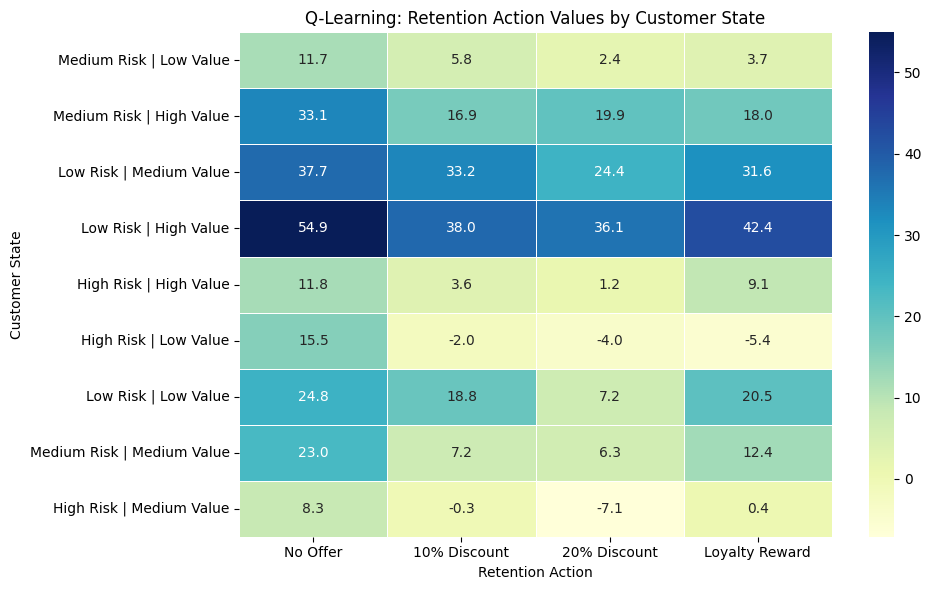

In [67]:
# ==========================================================
# Q-Learning Action Value Heatmap
# ==========================================================

plt.figure(figsize=(10, 6))

sns.heatmap(
    q_table,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Q-Learning: Retention Action Values by Customer State")
plt.xlabel("Retention Action")
plt.ylabel("Customer State")
plt.tight_layout()
plt.show()

### Business Insight — Retention Action Optimization

The Q-Learning heatmap compares the estimated value of four retention actions across nine customer states, classified by churn risk and customer lifetime value (CLTV).

- **No Offer dominates all customer states:** The agent assigns the highest Q-value to No Offer in every state. Under the current reward structure, the simulated benefits of discounts and loyalty rewards do not compensate for their assumed costs.
- **High-value customers require careful evaluation:** The Low Risk | High Value segment has the highest Q-value for No Offer (54.94). This suggests that providing incentives to customers who are already unlikely to churn may be unnecessary under the simulation assumptions.
- **High-risk customers present a retention challenge:** The High Risk | High Value segment has a Q-value of 11.84 for No Offer, while the High Risk | Low Value segment has a value of 15.47. These groups should be evaluated further to determine whether targeted interventions could create positive incremental value.
- **Incentives can produce negative simulated value:** For High Risk | Low Value customers, both discounts and the loyalty reward have negative Q-values. This highlights the importance of considering incentive costs rather than assuming that every retention campaign is beneficial.

**Managerial implication:** Businesses should avoid offering discounts indiscriminately and instead evaluate retention actions according to incremental customer value, churn risk, and intervention cost.

**Limitation:** These results depend on assumed retention effects and incentive costs, rather than actual campaign experiments. Therefore, the heatmap demonstrates the Q-Learning workflow but does not establish that No Offer is the optimal real-world strategy.

In [68]:
# ==========================================================
# Refined Retention Reward Model
# ==========================================================

# Illustrative business assumptions
retention_margin_rate = 0.05

risk_multiplier = {
    "Low": 0.25,
    "Medium": 0.65,
    "High": 1.00
}

# Keep the four existing actions and their assumed costs/lifts.
# These values are illustrative, not learned from actual campaigns.

def calculate_reward(customer, action_name):
    action = actions[action_name]

    risk = str(customer["Risk State"])
    cltv = float(customer["CLTV"])
    churn_probability = float(customer["Churn Probability"])

    # Effective offer lift varies by customer risk
    effective_lift = (
        action["retention_lift"] * risk_multiplier[risk]
    )

    baseline_retention = 1 - churn_probability

    offer_retention = min(
        1.0,
        baseline_retention + effective_lift
    )

    # Simulate whether the customer stays
    retained = np.random.binomial(1, offer_retention)

    # Illustrative financial reward
    reward = (
        retained * cltv * retention_margin_rate
        - action["cost"]
    )

    return reward


print("Refined reward model is ready.")
print("Retention margin assumption:", retention_margin_rate)
print("Risk multipliers:", risk_multiplier)

Refined reward model is ready.
Retention margin assumption: 0.05
Risk multipliers: {'Low': 0.25, 'Medium': 0.65, 'High': 1.0}


In [69]:
# ==========================================================
# Retrain the Agent with Refined Rewards
# ==========================================================

random.seed(42)
np.random.seed(42)

q_table = pd.DataFrame(
    0.0,
    index=states,
    columns=action_names
)

learning_rate = 0.10
epsilon = 0.20
episodes = 20000

for episode in range(episodes):

    customer = rl_data.sample(
        n=1,
        random_state=episode
    ).iloc[0]

    state = customer["State"]

    # Explore or exploit
    if random.random() < epsilon:
        action_name = random.choice(action_names)
    else:
        action_name = q_table.loc[state].idxmax()

    reward = calculate_reward(customer, action_name)

    # One-step terminal Q-value update
    old_value = q_table.loc[state, action_name]

    q_table.loc[state, action_name] = (
        old_value
        + learning_rate * (reward - old_value)
    )

print("Refined simulation completed.")

display(q_table.round(2))

Refined simulation completed.


,No Offer,10% Discount,20% Discount,Loyalty Reward
Medium Risk | Low Value,64.47,52.54,49.16,53.97
Medium Risk | High Value,99.58,105.19,106.23,95.05
Low Risk | Medium Value,173.63,179.85,152.92,186.64
Low Risk | High Value,247.93,198.33,212.60,213.09
High Risk | High Value,35.55,26.16,55.65,29.04
High Risk | Low Value,42.25,27.11,10.96,19.99
Low Risk | Low Value,119.00,92.97,106.01,132.16
Medium Risk | Medium Value,97.66,98.97,123.83,89.14
High Risk | Medium Value,38.26,15.20,35.88,89.00


In [70]:
# ==========================================================
# Recommended Action by Customer State
# ==========================================================

policy = pd.DataFrame({
    "Recommended Action": q_table.idxmax(axis=1),
    "Estimated Q-Value": q_table.max(axis=1)
})

display(policy.round(2))

,Recommended Action,Estimated Q-Value
Medium Risk | Low Value,No Offer,64.47
Medium Risk | High Value,20% Discount,106.23
Low Risk | Medium Value,Loyalty Reward,186.64
Low Risk | High Value,No Offer,247.93
High Risk | High Value,20% Discount,55.65
High Risk | Low Value,No Offer,42.25
Low Risk | Low Value,Loyalty Reward,132.16
Medium Risk | Medium Value,20% Discount,123.83
High Risk | Medium Value,Loyalty Reward,89.00


### Business Insight — Reinforcement Learning

The refined Q-Learning simulation generates differentiated retention recommendations based on predicted churn risk and customer lifetime value.

- **High-risk, high-value customers:** The agent recommends a 20% discount. This represents a potential strategy for protecting valuable customer relationships when churn risk is high.
- **Medium-risk, high-value customers:** A 20% discount is recommended, suggesting that the simulation assigns sufficient value to an incentive for this group.
- **Medium-risk, medium-value customers:** A 20% discount is preferred under the current reward assumptions.
- **Low-risk customers:** No Offer is preferred for high-value customers, while Loyalty Rewards are selected for low- and medium-value customers. This illustrates how retention decisions may differ according to customer risk and value.
- **High-risk, low-value customers:** No Offer is selected. Management should assess whether the expected value of retention justifies the cost of an incentive before allocating resources to this segment.

**Strategic implication:** Retention budgets should be allocated selectively rather than offering identical discounts to every customer. A differentiated policy can help balance customer retention objectives against incentive expenditure.

**Limitation:** These recommendations are outputs of a simulated reward model, not evidence that the actions will produce these results in a real business. The incentive effects and costs must be validated with actual retention campaign data before implementation.

In [71]:
# ==========================================================
# Compare Learned Policy Against No-Offer Baseline
# ==========================================================

policy_comparison = pd.DataFrame({
    "Recommended Action": q_table.idxmax(axis=1),
    "Recommended Q-Value": q_table.max(axis=1),
    "No-Offer Q-Value": q_table["No Offer"]
})

policy_comparison["Estimated Improvement"] = (
    policy_comparison["Recommended Q-Value"]
    - policy_comparison["No-Offer Q-Value"]
)

display(policy_comparison.round(2))

,Recommended Action,Recommended Q-Value,No-Offer Q-Value,Estimated Improvement
Medium Risk | Low Value,No Offer,64.47,64.47,0.00
Medium Risk | High Value,20% Discount,106.23,99.58,6.65
Low Risk | Medium Value,Loyalty Reward,186.64,173.63,13.00
Low Risk | High Value,No Offer,247.93,247.93,0.00
High Risk | High Value,20% Discount,55.65,35.55,20.11
High Risk | Low Value,No Offer,42.25,42.25,0.00
Low Risk | Low Value,Loyalty Reward,132.16,119.00,13.16
Medium Risk | Medium Value,20% Discount,123.83,97.66,26.16
High Risk | Medium Value,Loyalty Reward,89.00,38.26,50.75


### Business Insight — Evaluation of the Retention Policy

The comparison between the learned policy and the No Offer baseline indicates that the simulated agent assigns higher estimated values to selected retention actions for five customer states.

- **High Risk | Medium Value:** Loyalty Reward has the largest estimated improvement of 50.75, making this the most promising state for further investigation under the current simulation assumptions.
- **Medium Risk | Medium Value:** The 20% Discount produces an estimated improvement of 26.16.
- **High Risk | High Value:** The 20% Discount produces an estimated improvement of 20.11, suggesting a potential intervention for protecting valuable customer relationships.
- **Low Risk | Low Value:** Loyalty Reward produces an estimated improvement of 13.16.
- **Low Risk | Medium Value:** Loyalty Reward produces an estimated improvement of 13.00.

For the remaining four states, No Offer remains the preferred action because no alternative action has a higher estimated Q-value.

**Strategic implication:** The simulation supports testing targeted retention interventions rather than applying discounts uniformly. In particular, customers with high churn risk and medium customer value may be a priority for evaluating loyalty rewards.

**Limitation:** Estimated improvements are model-generated values, not actual revenue gains or proven reductions in churn. The recommended actions must be validated using real campaign outcomes before being adopted by a business.

# Integrated Business Findings

This project applied Supervised Learning, Unsupervised Learning, and Reinforcement Learning to the business problem of customer churn and retention strategy optimization using the Telco Customer Churn dataset.

The three approaches address different aspects of the decision-making process. Supervised learning predicts customer churn, unsupervised learning identifies customer segments with different behavioral and retention characteristics, and reinforcement learning simulates the selection of retention actions under an assumed reward structure.

##Key Findings

**1. Supervised Learning — Churn Prediction**

Logistic Regression emerged as the best-performing model among the four evaluated classifiers, achieving 80.93% accuracy and a ROC-AUC score of 85.37%. Its recall of 58.65% indicates that the model identifies a meaningful proportion of actual churners but still misses some customers who leave.

**2. Unsupervised Learning — Customer Segmentation**

K-Means identified four customer segments based on tenure, monthly charges, total charges, and customer lifetime value. The observed churn rates differed substantially across the segments:

- Cluster 0: 15.8%
- Cluster 1: 39.3%
- Cluster 2: 35.0%
- Cluster 3: 4.0%

Clusters 1 and 2 therefore represent important areas for further retention investigation. Cluster 3 demonstrated the lowest observed churn rate, while Cluster 0 also showed comparatively stable retention.

**3. Reinforcement Learning — Retention Action Optimization**

A Q-Learning simulation evaluated four actions: No Offer, 10% Discount, 20% Discount, and Loyalty Reward. The refined policy recommended different actions for different combinations of customer churn risk and value.

The largest estimated improvement over the No Offer baseline was 50.75 for the High Risk | Medium Value state, where the simulation preferred a Loyalty Reward. These values are simulated estimates rather than validated financial gains.

##  Overall Business Interpretation

Together, the three techniques demonstrate how machine learning can support a structured customer retention process: identify potential churners, understand the characteristics of customer segments, and evaluate alternative retention actions.

The combined framework provides a foundation for more targeted retention campaigns and better allocation of customer relationship management resources. Its recommendations should be validated against real campaign outcomes before operational implementation.